# FINAL RESULTS AND COMPARISONS  

In [22]:
import joblib 
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt

from sklearn.metrics import PrecisionRecallDisplay, ConfusionMatrixDisplay, classification_report
from sklearn.calibration import CalibrationDisplay

from churn.create_pipelines import engineer_lr_features, coerce_lgbm_dtypes
from churn.metrics import calibration_scores
from churn.config import TEST_DATA, ARTIFACTS_DIR, ROUNDS


In [23]:
# testing data 

X_test, y_test = joblib.load(TEST_DATA)
print(f"round 2 churn base rate: {round((y_test == 1).sum()/len(y_test), 3)*100}% ")

lgbm = joblib.load((ARTIFACTS_DIR / "lgbm_pipeline.joblib"))
logireg = joblib.load((ARTIFACTS_DIR / "logireg_pipeline.joblib"))

calib_lgbm = joblib.load((ARTIFACTS_DIR / "calib_lgbm_pipeline.joblib"))
calib_logireg = joblib.load((ARTIFACTS_DIR / "calib_logireg_pipeline.joblib"))

X_lr_test = engineer_lr_features(X_test, window_len=ROUNDS['r2']['win_len'])
X_lgbm_test = coerce_lgbm_dtypes(X_test)

# calib_* artifacts are dicts keyed by calibration method (sigmoid/isotonic)
models = [
    ("lgbm", lgbm, X_lgbm_test),
    ("logireg", logireg, X_lr_test),
    *[(f"calib_lgbm_{method}", model, X_lgbm_test) for method, model in calib_lgbm.items()],
    *[(f"calib_logireg_{method}", model, X_lr_test) for method, model in calib_logireg.items()],
]

probas = {name: model.predict_proba(X)[:, 1] for name, model, X in models}

results = pd.DataFrame([
    {"model": name, **calibration_scores(y_test, p, ref_probas=None)}
    for name, p in probas.items()
]).set_index("model")
results.sort_values(by = "expected_calibration_error")

round 2 churn base rate: 7.3% 


,expected_calibration_error,pr_auc,logloss,brier_loss
model,,,,
calib_lgbm_isotonic,0.0009,0.5305,0.1673,0.0451
calib_logireg_isotonic,0.0010,0.5071,0.1753,0.0461
calib_lgbm_sigmoid,0.0051,0.5399,0.1678,0.0454
calib_logireg_sigmoid,0.0055,0.5183,0.1760,0.0464
logireg,0.0128,0.5183,0.1783,0.0475
lgbm,0.0185,0.5399,0.1721,0.0469


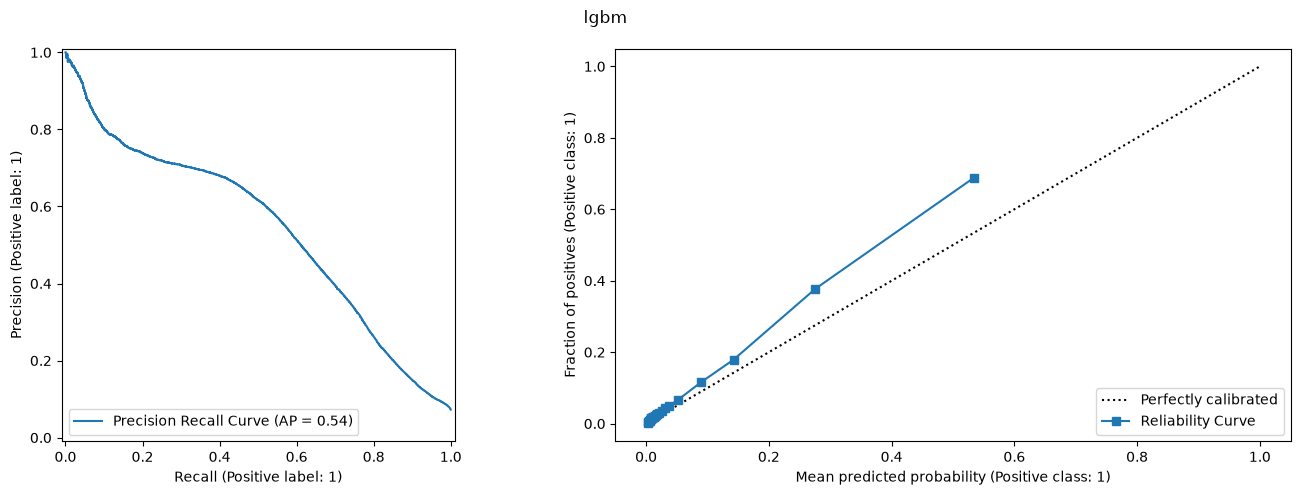

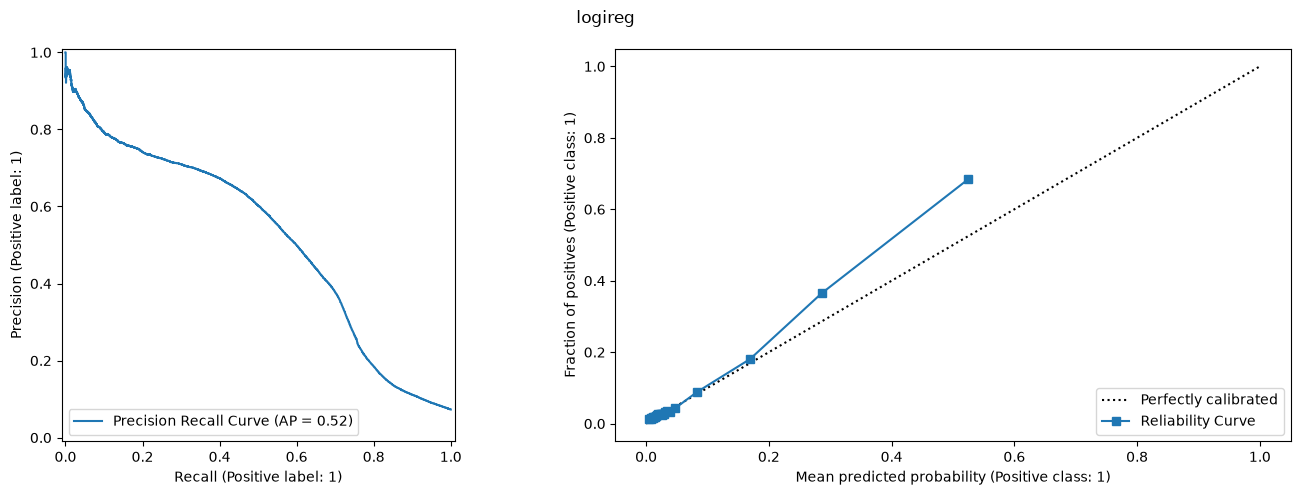

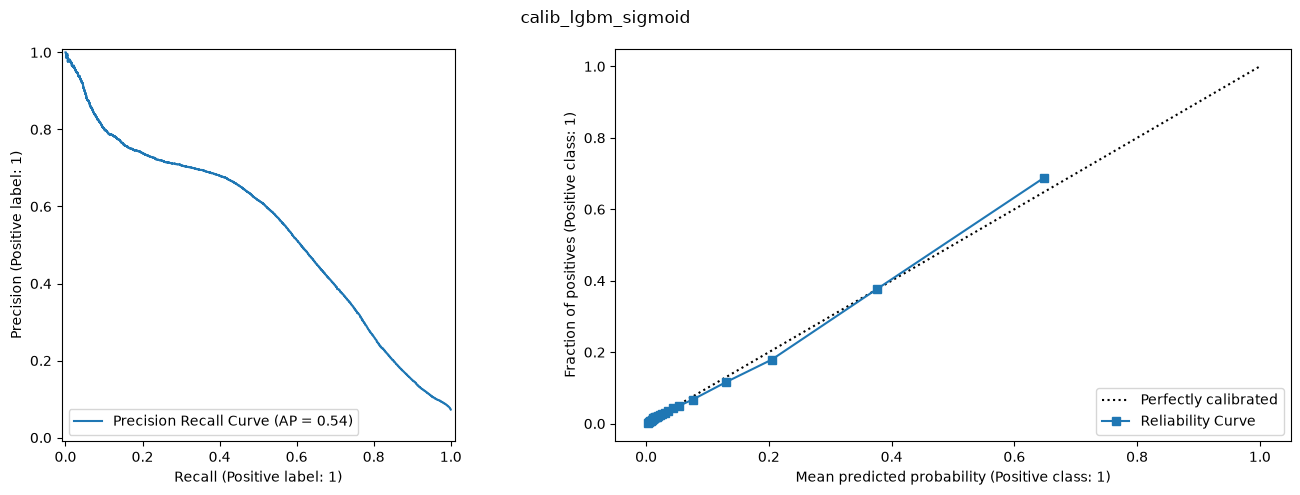

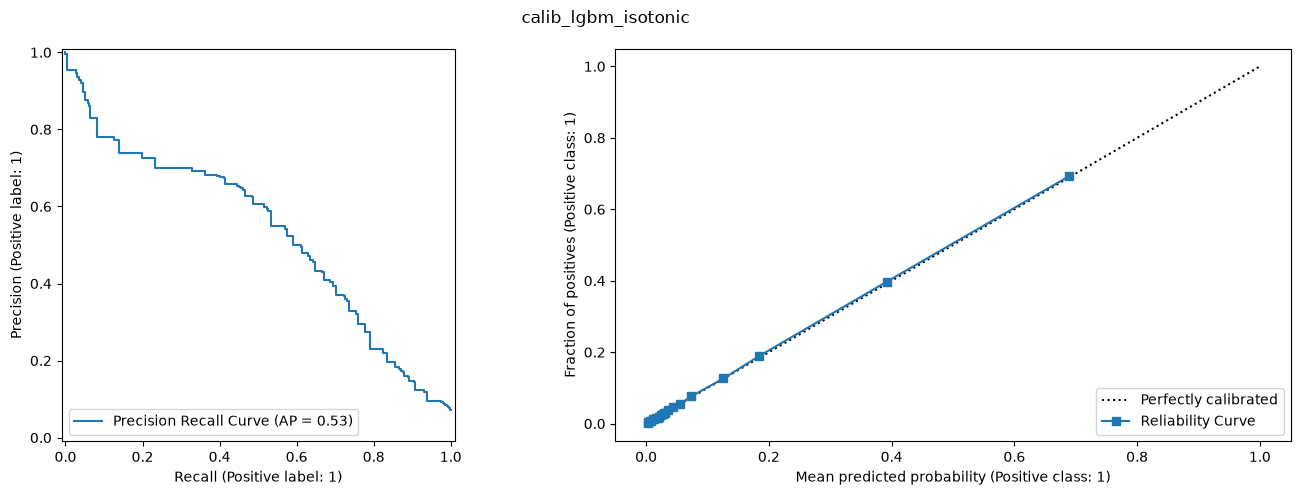

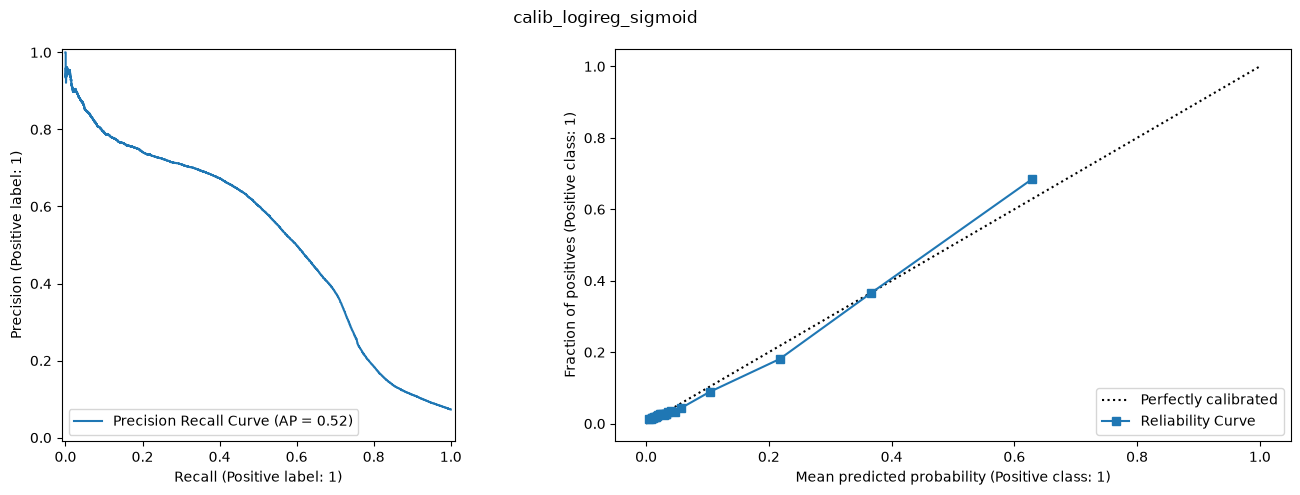

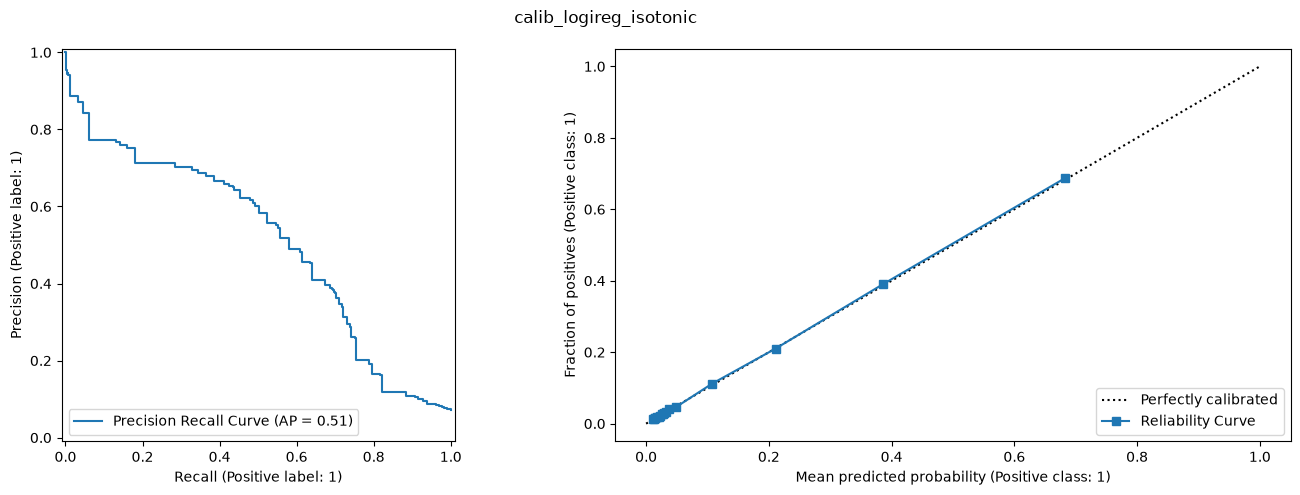

In [24]:
for name, p in probas.items():
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    PrecisionRecallDisplay.from_predictions(y_test, p, ax=axes[0], name="Precision Recall Curve")
    CalibrationDisplay.from_predictions(y_test, p, ax=axes[1], name="Reliability Curve", strategy="quantile", n_bins=25)
    fig.suptitle(name)
    fig.tight_layout()
    plt.show()

### chosen model:  
the winner model is **LightGBM calibrated using the isotonic regression method**. 
### justification:  
- it's nearly perfectly calibrated, as it reached `0.0009 ECE`, which means that the average deviation between the model's prediction and the empirical probability is 0.09%.  
- we also reached `0.53 Precision-Recall AUC`, which is **~8x the random chance base rate (0.07)**, so our model has a high capacity of classification regardless of any chosen threshold.  
- although isotonic calibrated logistic regression reached similar metrics, we did not choose it as it required a lot of feature engineering derived from EDA to reach such performance, where as LightGBM required nearly nothing. (see `churn.create_pipelines`).  

- **NOTE:** the positive class base rate changed from 5% in round 1 (training data) to 7% in round 2 (testing data), so getting such excellent metrics under such condition highlights our **model's temporall robustness.**


In [25]:
THRESHOLD = 0.2
print(classification_report(y_test, probas["calib_lgbm_isotonic"] >= THRESHOLD))

              precision    recall  f1-score   support

           0       0.97      0.95      0.96    642137
           1       0.50      0.61      0.55     50498

    accuracy                           0.93    692635
   macro avg       0.73      0.78      0.76    692635
weighted avg       0.93      0.93      0.93    692635



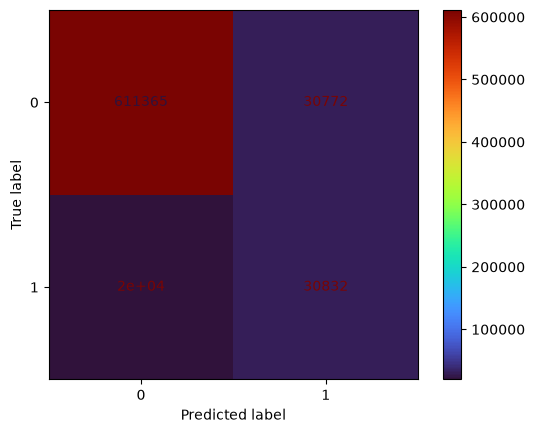

In [47]:
ConfusionMatrixDisplay.from_predictions(
                        y_test, probas["calib_lgbm_isotonic"] >= THRESHOLD,
                        colorbar=True,
                        cmap='turbo'
                        )

### at a fixed threshold : 0.2  
if we consider any user that has a 0.2 probability a churner, we would deploy this calibrated model at a 0.2 threshold. 

doing so, we are shrinking nearly 700,000 cases down to just 61,608 total alerts (True Positives + False Positives).  

We would only need to review this small subset, knowing that exactly half of the batch (50% precision) contains the users we are looking for.  

**Lift = Precision / Base Rate = 50 / 7.29 = ~7x**  
this means that an sample flagged by our model is ~7 times more likely to be a true positive than an sample chosen at random from the dataset.  this is an exceptionally strong result for an imbalanced dataset.
